In [18]:
import pybamm
import matplotlib.pyplot as plt
import numpy as np

In [19]:
parameter_values = pybamm.ParameterValues("Chen2020") #Importing parameter values from the parameter set
parameter_values.set_initial_state(0) # Set initial state of charge to 0%
initial_soc = 0
Q_nom = parameter_values["Nominal cell capacity [A.h]"]
V_nom = 3.6
P_rates = [(Q_nom * V_nom * P) + 0.1 for P in [1, 2, 3, 4]] # Define the P-rates for the charging experiment
sols = {}
print(P_rates)

[18.1, 36.1, 54.1, 72.1]


In [20]:
for P_rate in P_rates:
    CPCV_Charging = pybamm.Experiment([
        f"Charge at {P_rate} W until 4.2 V",
             "Hold at 4.2 V until C/20",
    ])
    sim = pybamm.Simulation(pybamm.lithium_ion.DFN(), experiment=CPCV_Charging, parameter_values=parameter_values)
    sols[P_rate] = sim.solve()

CP Phase Time end SoC for 18.1P: 73.92% at time 47.00 min
CV Phase Time for 18.1P: 27.54 min
Final SoC for 18.1P: 101.46% at time 102.70 min
CP Phase Time end SoC for 36.1P: 53.21% at time 17.31 min
CV Phase Time for 36.1P: 48.19 min
Final SoC for 36.1P: 101.40% at time 85.59 min
CP Phase Time end SoC for 54.1P: 33.81% at time 7.42 min
CV Phase Time for 54.1P: 66.87 min
Final SoC for 54.1P: 100.67% at time 76.24 min
CP Phase Time end SoC for 72.1P: 20.08% at time 3.33 min
CV Phase Time for 72.1P: 81.26 min
Final SoC for 72.1P: 101.34% at time 82.82 min


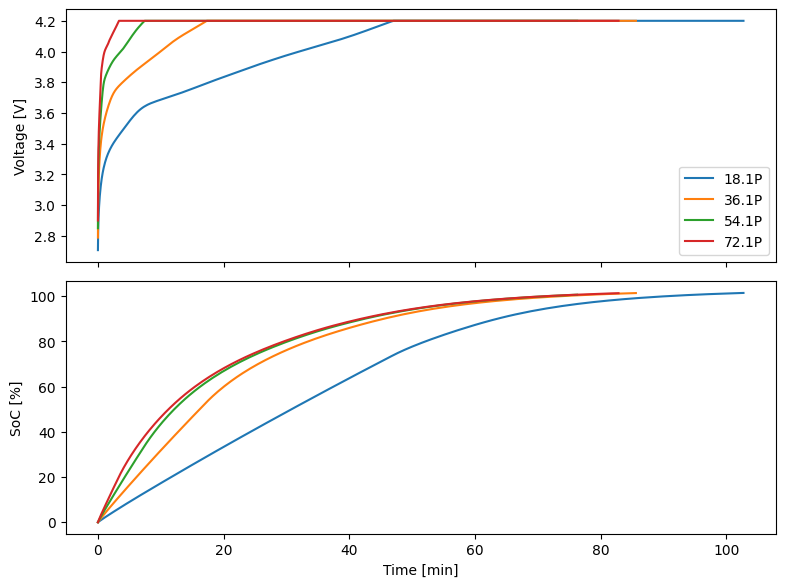

In [21]:
fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(8, 6))
for P_rates, sol in sols.items():
    t   = sol["Time [min]"].entries
    soc = (initial_soc - sol["Discharge capacity [A.h]"].entries / Q_nom) * 100
    ax1.plot(t, sol["Voltage [V]"].entries, label=f"{P_rates}P")
    ax2.plot(t, soc, label=f"{P_rates}P")
    t_end = sol.cycles[1]["Time [min]"].entries[-1]
    t_first_end = sol.cycles[0]["Time [min]"].entries[-1]
    t_second_end = sol.cycles[1]["Time [min]"].entries[-1]
    soc_end = np.interp(t_end, t, soc)
    soc_first_end = np.interp(t_first_end, t, soc)
    soc_second_end = np.interp(t_second_end, t, soc)
    CV_Phase_Time = soc_second_end - soc_first_end 
    print(f"CP Phase Time end SoC for {P_rates}P: {soc_first_end:.2f}% at time {t_first_end:.2f} min")
    print(f"CV Phase Time for {P_rates}P: {CV_Phase_Time:.2f} min")
    print(f"Final SoC for {P_rates}P: {soc_end:.2f}% at time {t_end:.2f} min")


ax1.set_ylabel("Voltage [V]");  ax1.legend()
ax2.set_ylabel("SoC [%]"); ax2.set_xlabel("Time [min]")
plt.tight_layout(); plt.show()